# Urban Green Space Analysis

**STAT 159 — Lab 11**

## Research Question

Which city has the most green area per capita in each year?

## Data Source

TidyTuesday — September 22, 2026

Original source: UN-Habitat Urban Indicators Database

## 1. Data Loading

We load the urban green space dataset from the TidyTuesday GitHub repository.

In [39]:
import os
import certifi
import pandas as pd

# Use the trusted CA certificate bundle
os.environ["SSL_CERT_FILE"] = certifi.where()

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-09-22/urban.csv"

df = pd.read_csv(url)

df.head()

,countryOrTerritoryName,cityCode,cityName,sdgSubRegion,sdgRegion,dataSource,footNote,year,averageShareOfGreenAreaInCityUrbanAreaPct,greenAreaPerCapitaM2
0,Afghanistan,AF_JALALABAD,Jalālābād,Southern Asia,Central Asia and Southern Asia,UN-Habitat Urban Indicators Database,Data on green areas per city is produced from ...,1990,8.351873,7.784019
1,Afghanistan,AF_JALALABAD,Jalālābād,Southern Asia,Central Asia and Southern Asia,UN-Habitat Urban Indicators Database,Data on green areas per city is produced from ...,2000,8.751470,7.803632
2,Afghanistan,AF_JALALABAD,Jalālābād,Southern Asia,Central Asia and Southern Asia,UN-Habitat Urban Indicators Database,Data on green areas per city is produced from ...,2010,8.670700,8.163923
3,Afghanistan,AF_JALALABAD,Jalālābād,Southern Asia,Central Asia and Southern Asia,UN-Habitat Urban Indicators Database,Data on green areas per city is produced from ...,2020,11.055533,15.174334
4,Afghanistan,AF_JALALABAD,Jalālābād,Southern Asia,Central Asia and Southern Asia,UN-Habitat Urban Indicators Database,Data on green areas per city is produced from ...,2025,NaN,NaN


In [40]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5600, 10)

Column names:
['countryOrTerritoryName', 'cityCode', 'cityName', 'sdgSubRegion', 'sdgRegion', 'dataSource', 'footNote', 'year', 'averageShareOfGreenAreaInCityUrbanAreaPct', 'greenAreaPerCapitaM2']


In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5600 entries, 0 to 5599
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   countryOrTerritoryName                     5600 non-null   str    
 1   cityCode                                   5560 non-null   str    
 2   cityName                                   5560 non-null   str    
 3   sdgSubRegion                               5560 non-null   str    
 4   sdgRegion                                  5600 non-null   str    
 5   dataSource                                 5600 non-null   str    
 6   footNote                                   5600 non-null   str    
 7   year                                       5600 non-null   int64  
 8   averageShareOfGreenAreaInCityUrbanAreaPct  4625 non-null   float64
 9   greenAreaPerCapitaM2                       4624 non-null   float64
dtypes: float64(2), int64(1), str(7)
mem

## 2. Data Quality Checks

Before conducting the analysis, we check for missing values,
duplicate observations, and available years.

In [42]:
df.isnull().sum()

countryOrTerritoryName                         0
cityCode                                      40
cityName                                      40
sdgSubRegion                                  40
sdgRegion                                      0
dataSource                                     0
footNote                                       0
year                                           0
averageShareOfGreenAreaInCityUrbanAreaPct    975
greenAreaPerCapitaM2                         976
dtype: int64

In [43]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [44]:
print("Available years:", sorted(df["year"].dropna().unique()))

print("\nKey variables:")
df[["cityName", "year", "greenAreaPerCapitaM2"]].describe(include="all")

Available years: [np.int64(1990), np.int64(2000), np.int64(2010), np.int64(2020), np.int64(2025)]

Key variables:


,cityName,year,greenAreaPerCapitaM2
count,5560,5600.000000,4624.000000
unique,1105,NaN,NaN
top,London,NaN,NaN
freq,10,NaN,NaN
mean,NaN,2009.000000,14.259125
std,NaN,12.807392,12.882982
min,NaN,1990.000000,0.000000
25%,NaN,2000.000000,4.525074
50%,NaN,2010.000000,10.553481
75%,NaN,2020.000000,20.486772


## 3. Data Cleaning

We remove observations with missing city names, years,
or green area per capita values to ensure valid comparisons.

We retain the original dataset and create a cleaned copy
for subsequent analysis.

In [45]:
clean_df = df.dropna(
    subset=["cityName", "year", "greenAreaPerCapitaM2"]
).copy()

print("Original observations:", len(df))
print("Cleaned observations:", len(clean_df))
print("Removed observations:", len(df) - len(clean_df))

Original observations: 5600
Cleaned observations: 4592
Removed observations: 1008


In [46]:
clean_df[["cityName", "year", "greenAreaPerCapitaM2"]].isnull().sum()

cityName                0
year                    0
greenAreaPerCapitaM2    0
dtype: int64

## 4. Data Analysis

We identify the city with the highest green area per capita
for each year.

We use Pandas to group observations by year and find
the maximum green area per capita within each group.

In [47]:
max_indices = clean_df.groupby("year")["greenAreaPerCapitaM2"].idxmax()

top_cities = clean_df.loc[
    max_indices,
    ["year", "cityName", "greenAreaPerCapitaM2"]
]

top_cities = top_cities.sort_values("year")

top_cities

,year,cityName,greenAreaPerCapitaM2
1100,1990,Bunia,78.974859
1221,2000,Fāqūs (Faqous),75.985952
1222,2010,Fāqūs (Faqous),73.026706
1223,2020,Fāqūs (Faqous),67.787589
1689,2025,Kozhikode (Calicut),57.473722


In [48]:
top_cities = top_cities.rename(
    columns={
        "year": "Year",
        "cityName": "City",
        "greenAreaPerCapitaM2": "Green Area Per Capita (m²)"
    }
)

top_cities.reset_index(drop=True)

,Year,City,Green Area Per Capita (m²)
0,1990,Bunia,78.974859
1,2000,Fāqūs (Faqous),75.985952
2,2010,Fāqūs (Faqous),73.026706
3,2020,Fāqūs (Faqous),67.787589
4,2025,Kozhikode (Calicut),57.473722


### Methodology

For each year, we selected the observation with the
highest green area per capita after removing records
with missing values in the relevant variables.

This allows us to compare the leading cities across
the five available years.

## 5. Data Visualization

We visualize the cities with the highest green area per capita
across the five available years using a horizontal bar chart.

Chart saved to: /Users/zhecenzhou/stat159/lab11/slides/green_space_top_cities.png


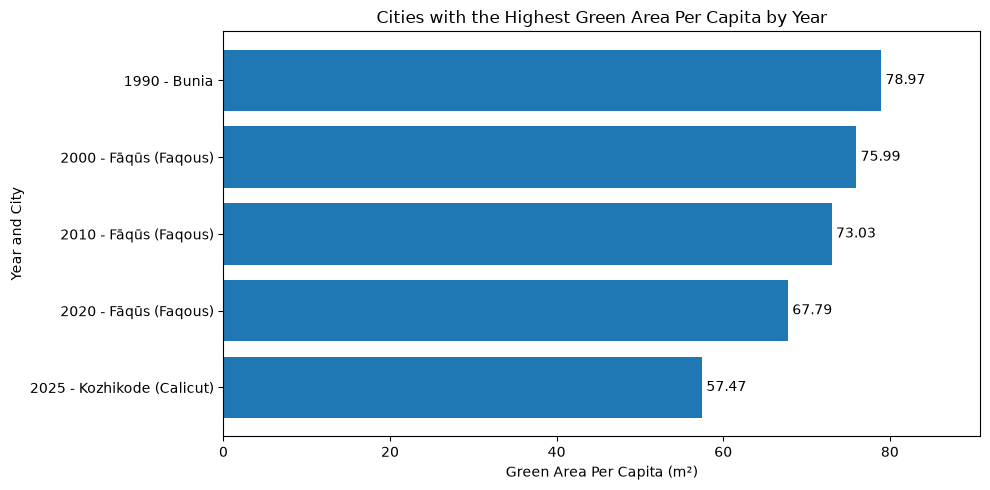

In [49]:
import matplotlib.pyplot as plt

labels = top_cities["Year"].astype(str) + " - " + top_cities["City"]
values = top_cities["Green Area Per Capita (m²)"]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(labels, values)

ax.set_xlabel("Green Area Per Capita (m²)")
ax.set_ylabel("Year and City")
ax.set_title("Cities with the Highest Green Area Per Capita by Year")

ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set_xlim(0, values.max() * 1.15)
ax.invert_yaxis()

plt.tight_layout()

from pathlib import Path

project_dir = Path.cwd()

if not (project_dir / "slides").is_dir():
    project_dir = project_dir.parent

chart_path = project_dir / "slides" / "green_space_top_cities.png"

fig.savefig(chart_path, dpi=200, bbox_inches="tight")
print(f"Chart saved to: {chart_path}")

plt.show()

### Key Findings

Fāqūs (Faqous) recorded the highest green area per capita
in three consecutive observed years: 2000, 2010, and 2020.

The highest observed green area per capita decreased from
78.97 m² in 1990 to 57.47 m² in 2025.

However, this does not necessarily indicate an overall
decline in urban green space, since the leading city
differs across years.